# Smart Home Water and Energy Prediction with Virtual Optimization

This notebook implements the methodology described in Chapter 3.

## Data files expected

Place the files in a folder named `data` beside this notebook.

Recommended names:

- `data/smart_water_meter.csv`
- `data/smart_sensors.csv`
- `data/energydata_complete.csv`

The code:
1. analyses the Zenodo water and IoT data separately;
2. analyses the UCI Appliances Energy Prediction data separately;
3. compares baseline, Linear/Ridge, Random Forest and Gradient Boosting models;
4. optionally trains an LSTM model;
5. creates a transparent Python-based virtual optimization simulation;
6. saves results, figures and trained models.

The water and energy datasets are **not merged at record level**.


The energy forecast estimates the next 10-minute interval using only past measurements. Model selection uses validation RMSE, with persistence included. The test set is used after selection.

The water field `v2` has no verified consumption definition in the supplied documentation. The default water analysis is therefore a diagnostic analysis of the signed meter field, not a water-volume forecast; no water saving is estimated. Set a documented water configuration only after verifying the units and measurement meaning.

Run from top to bottom. The source files must be in `data`. The execution record includes file hashes and package versions.


In [1]:
# 00. Environment and imports

from __future__ import annotations

import json
import math
import os
import random
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler



SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs_corrected"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, MODEL_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
import hashlib, platform, importlib.metadata
RUN_RECORD = {"python": platform.python_version(), "seed": SEED, "packages": {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "scikit-learn", "matplotlib", "joblib"]}, "files": {}}
def record_file(path):
    RUN_RECORD["files"][path.name] = {"sha256": hashlib.sha256(path.read_bytes()).hexdigest(), "bytes": path.stat().st_size}


Project directory: /content
Data directory: /content/data


## 1. Shared utility functions

In [2]:
def find_first_existing_file(candidates: List[str]) -> Path:
    for name in candidates:
        path = DATA_DIR / name
        if path.exists():
            return path
    raise FileNotFoundError(
        "None of the expected files were found. Checked:\n" +
        "\n".join(str(DATA_DIR / name) for name in candidates)
    )


def detect_datetime_column(df: pd.DataFrame) -> str:
    preferred = ["date", "datetime", "timestamp", "time", "Date", "Timestamp"]
    for col in preferred:
        if col in df.columns:
            return col

    for col in df.columns:
        parsed = pd.to_datetime(df[col], errors="coerce")
        if parsed.notna().mean() > 0.8:
            return col

    raise ValueError("No reliable datetime column could be detected.")


def parse_and_sort_time(df: pd.DataFrame, datetime_col: Optional[str] = None) -> pd.DataFrame:
    result = df.copy()
    datetime_col = datetime_col or detect_datetime_column(result)
    result[datetime_col] = pd.to_datetime(result[datetime_col], errors="coerce")
    result = result.dropna(subset=[datetime_col]).sort_values(datetime_col)
    result = result.drop_duplicates(subset=[datetime_col], keep="last")
    return result.set_index(datetime_col)


def infer_sampling_interval(index: pd.DatetimeIndex) -> pd.Timedelta:
    diffs = index.to_series().diff().dropna()
    if diffs.empty:
        return pd.Timedelta(0)
    return diffs.mode().iloc[0]


def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    result = df.copy()
    idx = result.index

    result["hour"] = idx.hour
    result["dayofweek"] = idx.dayofweek
    result["weekend"] = (idx.dayofweek >= 5).astype(int)
    result["month"] = idx.month
    result["dayofmonth"] = idx.day
    result["weekofyear"] = idx.isocalendar().week.astype(int)

    result["hour_sin"] = np.sin(2 * np.pi * result["hour"] / 24)
    result["hour_cos"] = np.cos(2 * np.pi * result["hour"] / 24)
    result["dow_sin"] = np.sin(2 * np.pi * result["dayofweek"] / 7)
    result["dow_cos"] = np.cos(2 * np.pi * result["dayofweek"] / 7)

    return result


def add_lag_rolling_features(
    df: pd.DataFrame,
    target_col: str,
    lags: List[int],
    rolling_windows: List[int]
) -> pd.DataFrame:
    result = df.copy()

    for lag in lags:
        result[f"{target_col}_lag_{lag}"] = result[target_col].shift(lag)

    shifted = result[target_col].shift(1)
    for window in rolling_windows:
        result[f"{target_col}_roll_mean_{window}"] = shifted.rolling(window).mean()
        result[f"{target_col}_roll_std_{window}"] = shifted.rolling(window).std()
        result[f"{target_col}_roll_max_{window}"] = shifted.rolling(window).max()

    return result


def chronological_split(
    df: pd.DataFrame,
    train_ratio: float = 0.70,
    valid_ratio: float = 0.15
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    if not 0 < train_ratio < 1:
        raise ValueError("train_ratio must be between 0 and 1.")
    if not 0 < valid_ratio < 1:
        raise ValueError("valid_ratio must be between 0 and 1.")
    if train_ratio + valid_ratio >= 1:
        raise ValueError("train_ratio + valid_ratio must be less than 1.")

    n = len(df)
    train_end = int(n * train_ratio)
    valid_end = int(n * (train_ratio + valid_ratio))

    return (
        df.iloc[:train_end].copy(),
        df.iloc[train_end:valid_end].copy(),
        df.iloc[valid_end:].copy()
    )


def safe_mape(y_true: np.ndarray, y_pred: np.ndarray, epsilon: float = 1e-8) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > epsilon

    if mask.sum() == 0:
        return np.nan

    return float(
        np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    )


def regression_metrics(
    y_true: pd.Series,
    y_pred: np.ndarray,
    model_name: str,
    dataset_name: str,
    baseline_rmse: Optional[float] = None
) -> Dict[str, float]:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    mape = safe_mape(y_true.to_numpy(), np.asarray(y_pred))

    improvement = np.nan
    if baseline_rmse is not None and baseline_rmse > 0:
        improvement = ((baseline_rmse - rmse) / baseline_rmse) * 100

    return {
        "dataset": dataset_name,
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_percent": mape,
        "RMSE_improvement_over_baseline_percent": improvement
    }


def plot_actual_vs_predicted(
    y_true: pd.Series,
    y_pred: np.ndarray,
    title: str,
    output_name: str,
    max_points: int = 1000
) -> None:
    n = min(len(y_true), max_points)

    plt.figure(figsize=(12, 5))
    plt.plot(y_true.index[:n], y_true.iloc[:n], label="Actual")
    plt.plot(y_true.index[:n], y_pred[:n], label="Predicted")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Target")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / output_name, dpi=300)
    plt.show()


def plot_residuals(
    y_true: pd.Series,
    y_pred: np.ndarray,
    title: str,
    output_name: str
) -> None:
    residuals = y_true.to_numpy() - np.asarray(y_pred)

    plt.figure(figsize=(8, 5))
    plt.scatter(np.asarray(y_pred), residuals, alpha=0.4)
    plt.axhline(0)
    plt.title(title)
    plt.xlabel("Predicted value")
    plt.ylabel("Residual")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / output_name, dpi=300)
    plt.show()

def compare_models(train, valid, test, target, features, models, label):
    # Selection is completed before evaluating any test prediction.
    Xtr, ytr = train[features], train[target]
    Xva, yva = valid[features], valid[target]
    lag = target + "_lag_1"
    valid_rows = [regression_metrics(yva, valid[lag].to_numpy(), "Naive Persistence", label)]
    fitted = {}
    for name, estimator in models.items():
        model = clone(estimator).fit(Xtr, ytr)
        valid_rows.append(regression_metrics(yva, model.predict(Xva), name, label))
    validation = pd.DataFrame(valid_rows).sort_values("RMSE").reset_index(drop=True)
    selected = validation.iloc[0]["model"]
    validation.to_csv(TABLE_DIR / f"{label.lower()}_validation_results.csv", index=False)
    Xfit = pd.concat([Xtr, Xva]); yfit = pd.concat([ytr, yva])
    ytest = test[target]
    predictions = {"Naive Persistence": test[lag].to_numpy()}
    baseline_rmse = mean_squared_error(ytest, predictions["Naive Persistence"]) ** 0.5
    rows = [regression_metrics(ytest, predictions["Naive Persistence"], "Naive Persistence", label, baseline_rmse)]
    for name, estimator in models.items():
        fitted[name] = clone(estimator).fit(Xfit, yfit)
        predictions[name] = fitted[name].predict(test[features])
        rows.append(regression_metrics(ytest, predictions[name], name, label, baseline_rmse))
    results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
    results["selected_on_validation"] = results["model"].eq(selected)
    results.to_csv(TABLE_DIR / f"{label.lower()}_model_results.csv", index=False)
    RUN_RECORD[label.lower()] = {"selected_model": selected, "splits": {key: {"rows": len(frame), "start": str(frame.index.min()), "end": str(frame.index.max())} for key,frame in [("train",train),("validation",valid),("test",test)]}, "features": features, "tuning": "Not performed; fixed parameters", "parameters": {name: str(m.get_params()) for name,m in models.items()}}
    print("Selected using validation:", selected)
    display(validation); display(results)
    return results, fitted, predictions, selected


# Part A — Zenodo Water and IoT Analysis

# Part A — Water Meter Diagnostic Analysis

An undocumented field is not assumed to measure water consumption. The hourly timeline is retained while creating lagged features. Missing observations remain unknown, not zero consumption.


Water file: /content/data/smart_water_meter.csv
Sensor file: /content/data/smart_sensors.csv
Original water shape: (3108, 11)
Water columns: ['id', 'result_time', 'nodeid', 'v1', 'v2', 'v3', 'v4', 'v5', 'image_id', 'v6', 'v7']
Detected time column: result_time
Water period: 2020-12-18 00:03:52 to 2021-04-03 17:06:53
Timestamped records: 3107
Numeric measurement candidates: ['v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7']
Target construction: signed v2 diagnostic; physical meaning and units unverified
Target construction: signed v2 diagnostic; physical meaning and units unverified
Usable raw target rows: 3107


,water_target
count,3.107000e+03
mean,9.908668e+02
std,3.818164e+05
min,-3.004000e+06
25%,0.000000e+00
50%,0.000000e+00
75%,2.000000e+01
max,3.004010e+06


Sensor parse error: Error tokenizing data. C error: EOF inside string starting at row 102865
Hourly aligned water shape: (2562, 1)
Hourly period: 2020-12-18 00:00:00 to 2021-04-03 17:00:00


,count,mean,std,min,25%,50%,75%,max
water_target,1568.0,1963.407526,440137.876962,-3004000.0,0.0,10.0,50.0,3004001.0


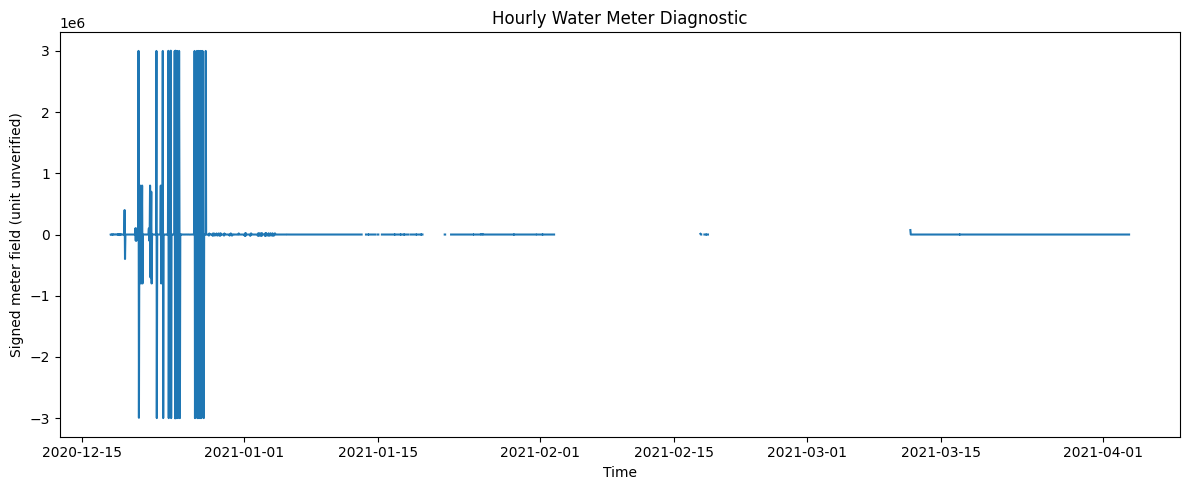

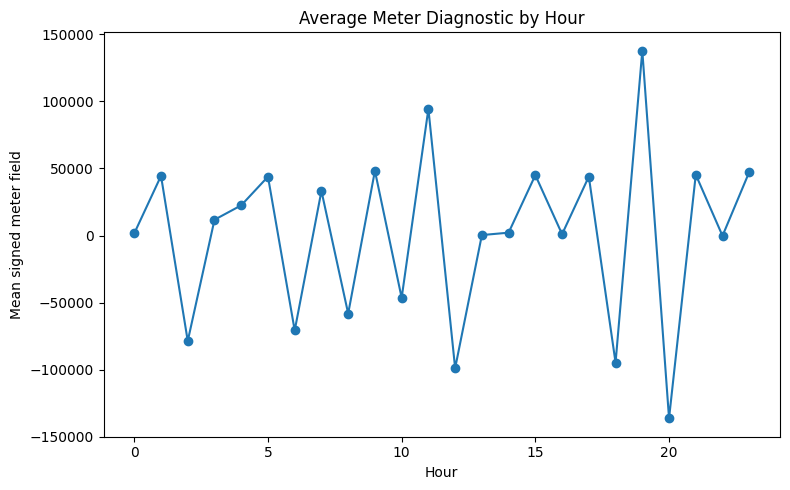

Usable modelling rows: 1538
Train rows: 1076
Validation rows: 231
Test rows: 231
Predictor count: 28
Selected using validation: Naive Persistence


,dataset,model,MAE,RMSE,R2,MAPE_percent,RMSE_improvement_over_baseline_percent
0,Water,Naive Persistence,33.896104,58.313231,-0.539786,138.868913,NaN
1,Water,Random Forest,62.081580,171.021778,-12.244297,264.797962,NaN
2,Water,Gradient Boosting,1345.172059,1914.335518,-1658.442393,5762.139048,NaN
3,Water,Linear Regression,24032.793306,30416.942888,-418944.173051,110335.762490,NaN
4,Water,Ridge Regression,24102.247702,30436.196466,-419474.715944,110592.638673,NaN


,dataset,model,MAE,RMSE,R2,MAPE_percent,RMSE_improvement_over_baseline_percent,selected_on_validation
0,Water,Naive Persistence,41.861472,79.818517,-0.837857,154.319588,0.000000,True
1,Water,Random Forest,121.266976,382.876189,-41.288382,350.607544,-379.683415,False
2,Water,Gradient Boosting,1347.765056,2204.953087,-1401.500606,5853.597842,-2662.458096,False
3,Water,Ridge Regression,19546.799547,24581.267930,-174305.230442,84919.934338,-30696.447773,False
4,Water,Linear Regression,19568.793574,24649.777598,-175278.191092,84412.078372,-30782.279571,False


In [3]:
# COMPLETE FIXED WATER PIPELINE
# This cell replaces the previous water loading, preparation, splitting,
# baseline, and model-comparison cells.

from pathlib import Path

# -------------------------------------------------------------------
# A. Locate the water file and optionally the IoT sensor file
# -------------------------------------------------------------------

def locate_file(names):
    search_folders = [
        DATA_DIR,
        Path.cwd(),
        Path("/content"),
        Path("/content/data"),
        Path("/mnt/data")
    ]

    checked = []

    for folder in search_folders:
        for name in names:
            candidate = folder / name
            checked.append(str(candidate))

            if candidate.exists() and candidate.stat().st_size > 0:
                return candidate

    raise FileNotFoundError(
        "Required data file was not found or was empty.\nChecked:\n"
        + "\n".join(checked)
    )


water_path = locate_file([
    "smart_water_meter.csv",
    "water_meter.csv",
    "water.csv"
])

sensor_path = None

for folder in [
    DATA_DIR,
    Path.cwd(),
    Path("/content"),
    Path("/content/data"),
    Path("/mnt/data")
]:
    for name in [
        "smart_sensors.csv",
        "sensors.csv",
        "iot_sensors.csv"
    ]:
        candidate = folder / name

        if candidate.exists() and candidate.stat().st_size > 0:
            sensor_path = candidate
            break

    if sensor_path is not None:
        break

print("Water file:", water_path)

if sensor_path is None:
    print(
        "IoT sensor file was not found or was empty. "
        "The water pipeline will continue using water-meter variables only."
    )
else:
    print("Sensor file:", sensor_path)


# -------------------------------------------------------------------
# B. Load and parse the water data
# -------------------------------------------------------------------

record_file(water_path)
water_raw = pd.read_csv(water_path)

if water_raw.empty:
    raise ValueError("The water CSV contains no records.")

print("Original water shape:", water_raw.shape)
print("Water columns:", water_raw.columns.tolist())


def detect_water_datetime_column(df):
    preferred = [
        "result_time",
        "timestamp",
        "datetime",
        "date",
        "time",
        "Date",
        "Timestamp"
    ]

    for col in preferred:
        if col in df.columns:
            parsed = pd.to_datetime(df[col], errors="coerce")

            if parsed.notna().sum() > 0:
                return col

    for col in df.columns:
        parsed = pd.to_datetime(df[col], errors="coerce")

        if parsed.notna().mean() >= 0.80:
            return col

    raise ValueError(
        "No valid datetime column could be detected in the water file."
    )


water_datetime_col = detect_water_datetime_column(water_raw)

water_raw[water_datetime_col] = pd.to_datetime(
    water_raw[water_datetime_col],
    errors="coerce"
)

water = (
    water_raw
    .dropna(subset=[water_datetime_col])
    .sort_values(water_datetime_col)
    .drop_duplicates(subset=[water_datetime_col], keep="last")
    .set_index(water_datetime_col)
)

if water.empty:
    raise ValueError(
        "No valid water records remain after timestamp parsing."
    )

print("Detected time column:", water_datetime_col)
print("Water period:", water.index.min(), "to", water.index.max())
print("Timestamped records:", len(water))


# -------------------------------------------------------------------
# C. Convert possible meter fields to numeric and identify target
# -------------------------------------------------------------------

identifier_columns = {
    "id",
    "nodeid",
    "node_id",
    "image_id"
}

numeric_candidates = []

for col in water.columns:
    converted = pd.to_numeric(water[col], errors="coerce")

    if (
        col.lower() not in identifier_columns
        and converted.notna().sum() > 0
    ):
        water[col] = converted
        numeric_candidates.append(col)

if not numeric_candidates:
    raise ValueError(
        "No usable numeric measurement columns were found."
    )

print("Numeric measurement candidates:", numeric_candidates)

# Explicit configuration; do not infer meter semantics from numeric variation.
WATER_SOURCE_COLUMN = "v2"
WATER_TARGET_KIND = "diagnostic"  # diagnostic, interval, or cumulative
WATER_UNITS = None
WATER_DEFINITION_SOURCE = None
WATER_SCALE = 1.0
WATER_VALIDATED = WATER_TARGET_KIND in {"interval", "cumulative"}
if WATER_VALIDATED and (not WATER_UNITS or not WATER_DEFINITION_SOURCE):
    raise ValueError("Document the water units and definition source before modelling consumption.")
water_source_col = WATER_SOURCE_COLUMN
if water_source_col not in numeric_candidates:
    raise ValueError("Configured water field is unavailable.")
source = pd.to_numeric(water[water_source_col], errors="coerce") * WATER_SCALE
if WATER_TARGET_KIND == "cumulative":
    water["water_target"] = source.diff().where(source.diff() >= 0)
    target_method = "documented cumulative differences; negative resets left missing"
elif WATER_TARGET_KIND == "interval":
    water["water_target"] = source.where(source >= 0)
    target_method = "documented interval consumption"
elif WATER_TARGET_KIND == "diagnostic":
    water["water_target"] = source
    target_method = "signed v2 diagnostic; physical meaning and units unverified"
else:
    raise ValueError("Unknown water target kind")
print("Target construction:", target_method)
RUN_RECORD["water_target"] = {"kind": WATER_TARGET_KIND, "column": water_source_col, "units": WATER_UNITS, "definition_source": WATER_DEFINITION_SOURCE}

water = water.replace(
    [np.inf, -np.inf],
    np.nan
)



if water.empty:
    raise ValueError(
        "The selected water target produced no usable observations. "
        "Inspect the source column and target definition."
    )

print("Target construction:", target_method)
print("Usable raw target rows:", len(water))
display(water["water_target"].describe())


# -------------------------------------------------------------------
# D. Resample water data to hourly intervals
# -------------------------------------------------------------------

WATER_RESAMPLE_RULE = "1h"

water_aligned = pd.DataFrame(
    index=water["water_target"]
    .resample(WATER_RESAMPLE_RULE)
    .sum(min_count=1)
    .index
)

water_aligned["water_target"] = (
    water["water_target"]
    .resample(WATER_RESAMPLE_RULE)
    .sum(min_count=1)
)

# Other meter fields and sensor channels have no verified mapping here.
# They are excluded rather than treated as occupancy or consumption predictors.
if sensor_path is not None:
    record_file(sensor_path)
    try:
        sensors_raw = pd.read_csv(sensor_path)
        print("Sensor file parsed:", sensors_raw.shape, "; not used without verified channel mapping.")
        RUN_RECORD["sensor_status"] = {"parsed": True, "rows": len(sensors_raw), "used": False}
    except Exception as exc:
        print("Sensor parse error:", exc)
        RUN_RECORD["sensor_status"] = {"parsed": False, "error": str(exc), "used": False}

water_aligned = water_aligned.replace(
    [np.inf, -np.inf],
    np.nan
)

# Keep missing hours until all lags are constructed.
RUN_RECORD["water_grid"] = {"total_hours": len(water_aligned), "observed_hours": int(water_aligned["water_target"].notna().sum()), "missing_hours": int(water_aligned["water_target"].isna().sum())}

# Remove completely empty predictors.
empty_predictors = [
    col
    for col in water_aligned.columns
    if col != "water_target"
    and water_aligned[col].isna().all()
]

if empty_predictors:
    water_aligned = water_aligned.drop(
        columns=empty_predictors
    )

print("Hourly aligned water shape:", water_aligned.shape)
print(
    "Hourly period:",
    water_aligned.index.min(),
    "to",
    water_aligned.index.max()
)


# -------------------------------------------------------------------
# F. Basic water exploratory outputs
# -------------------------------------------------------------------

display(water_aligned.describe().T)

plt.figure(figsize=(12, 5))
plt.plot(
    water_aligned.index,
    water_aligned["water_target"]
)
plt.title("Hourly Water Meter Diagnostic")
plt.xlabel("Time")
plt.ylabel("Signed meter field (unit unverified)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "water_time_series.png",
    dpi=300
)
plt.show()

water_hourly_profile = (
    water_aligned
    .assign(hour=water_aligned.index.hour)
    .groupby("hour")["water_target"]
    .mean()
)

plt.figure(figsize=(8, 5))
plt.plot(
    water_hourly_profile.index,
    water_hourly_profile.values,
    marker="o"
)
plt.title("Average Meter Diagnostic by Hour")
plt.xlabel("Hour")
plt.ylabel("Mean signed meter field")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "water_hourly_profile.png",
    dpi=300
)
plt.show()


# -------------------------------------------------------------------
# G. Feature engineering
# -------------------------------------------------------------------

water_features_df = add_time_features(
    water_aligned
)

# Hourly lags.
for lag in [1, 2, 3, 6, 12, 24]:
    water_features_df[
        f"water_target_lag_{lag}"
    ] = water_features_df[
        "water_target"
    ].shift(lag)

# Shift before rolling to prevent target leakage.
past_target = water_features_df[
    "water_target"
].shift(1)

for window in [3, 6, 12, 24]:
    water_features_df[
        f"water_target_roll_mean_{window}"
    ] = past_target.rolling(
        window=window,
        min_periods=1
    ).mean()

    water_features_df[
        f"water_target_roll_std_{window}"
    ] = past_target.rolling(
        window=window,
        min_periods=2
    ).std()

    water_features_df[
        f"water_target_roll_max_{window}"
    ] = past_target.rolling(
        window=window,
        min_periods=1
    ).max()

water_features_df = water_features_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Only the target and first lag must be present.
# Other missing predictors are handled by the imputer.
water_features_df = water_features_df.dropna(
    subset=[
        "water_target",
        "water_target_lag_1"
    ]
)

print("Usable modelling rows:", len(water_features_df))

if len(water_features_df) < 30:
    raise ValueError(
        f"Only {len(water_features_df)} modelling rows remain. "
        "The selected water variable or sampling frequency "
        "requires further inspection."
    )


# -------------------------------------------------------------------
# H. Chronological train-validation-test split
# -------------------------------------------------------------------

WATER_TARGET = "water_target"

water_feature_cols = [
    col
    for col in water_features_df.columns
    if (
        col != WATER_TARGET
        and pd.api.types.is_numeric_dtype(
            water_features_df[col]
        )
        and not water_features_df[col].isna().all()
    )
]

if "water_target_lag_1" not in water_feature_cols:
    raise ValueError(
        "The persistence lag feature was not generated."
    )

number_of_rows = len(water_features_df)

train_end = int(number_of_rows * 0.70)
validation_end = int(number_of_rows * 0.85)

water_train = water_features_df.iloc[
    :train_end
].copy()

water_valid = water_features_df.iloc[
    train_end:validation_end
].copy()

water_test = water_features_df.iloc[
    validation_end:
].copy()

if min(
    len(water_train),
    len(water_valid),
    len(water_test)
) == 0:
    raise ValueError(
        "A chronological data split is empty."
    )

Xw_train = water_train[
    water_feature_cols
].copy()

yw_train = water_train[
    WATER_TARGET
].astype(float).copy()

Xw_valid = water_valid[
    water_feature_cols
].copy()

yw_valid = water_valid[
    WATER_TARGET
].astype(float).copy()

Xw_test = water_test[
    water_feature_cols
].copy()

yw_test = water_test[
    WATER_TARGET
].astype(float).copy()

Xw_fit = pd.concat(
    [Xw_train, Xw_valid],
    axis=0
)

yw_fit = pd.concat(
    [yw_train, yw_valid],
    axis=0
)

print("Train rows:", len(Xw_train))
print("Validation rows:", len(Xw_valid))
print("Test rows:", len(Xw_test))
print("Predictor count:", len(water_feature_cols))


# -------------------------------------------------------------------
# I. Baseline and machine-learning models
# -------------------------------------------------------------------

linear_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

ridge_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        Ridge(alpha=1.0)
    )
])

rf_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=-1
        )
    )
])

gb_pipe = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=3,
            random_state=SEED
        )
    )
])

water_models = {
    "Linear Regression": linear_pipe,
    "Ridge Regression": ridge_pipe,
    "Random Forest": rf_pipe,
    "Gradient Boosting": gb_pipe
}

water_results_df, fitted_water_models, water_predictions, best_water_name = compare_models(
    water_train, water_valid, water_test, WATER_TARGET, water_feature_cols, water_models, "Water")


Best water model: Naive Persistence


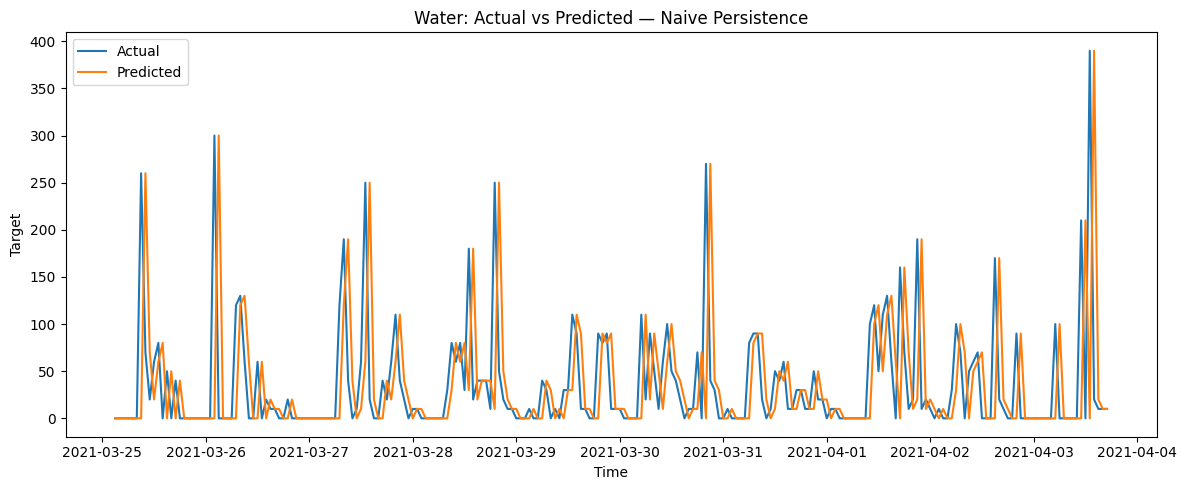

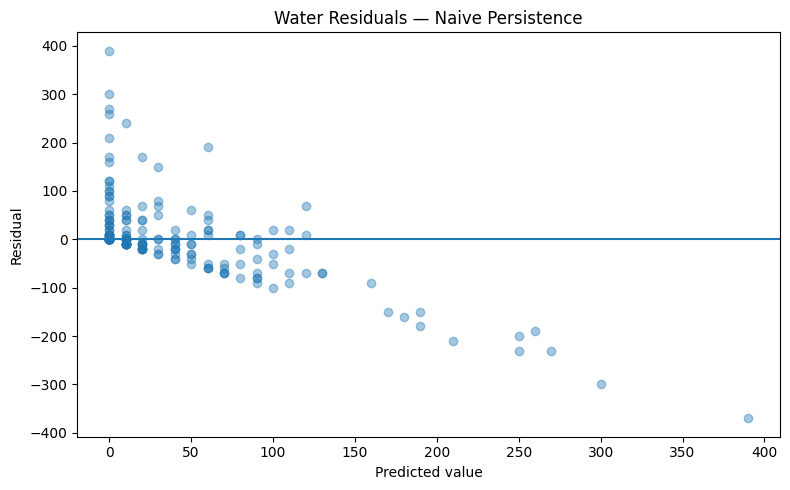

In [4]:
# 11. Select and interpret the best water model

best_water_model = fitted_water_models.get(best_water_name)
best_water_pred = water_predictions[best_water_name]

print("Best water model:", best_water_name)

plot_actual_vs_predicted(
    yw_test,
    best_water_pred,
    title=f"Water: Actual vs Predicted — {best_water_name}",
    output_name="water_actual_vs_predicted.png"
)

plot_residuals(
    yw_test,
    best_water_pred,
    title=f"Water Residuals — {best_water_name}",
    output_name="water_residuals.png"
)

if best_water_model is not None:
    joblib.dump(best_water_model, MODEL_DIR / "best_water_model.joblib")

if best_water_name in {"Random Forest", "Gradient Boosting"}:
    perm = permutation_importance(
        best_water_model,
        Xw_test,
        yw_test,
        n_repeats=10,
        random_state=SEED,
        scoring="neg_root_mean_squared_error"
    )

    water_importance = pd.DataFrame({
        "feature": water_feature_cols,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std
    }).sort_values("importance_mean", ascending=False)

    display(water_importance.head(20))
    water_importance.to_csv(TABLE_DIR / "water_feature_importance.csv", index=False)

# Part B — UCI Appliances Energy Prediction

In [17]:
# 12. Load UCI energy dataset (downloads a fresh, complete copy)

import os, subprocess
from pathlib import Path

EXPECTED_ROWS = 19735
energy_path = Path("/content/energydata_complete.csv")

# a) Remove any old / broken copies anywhere under /content
for name in ["energydata_complete.csv", "appliances_energy_prediction.csv", "energy.csv"]:
    for p in Path("/content").rglob(name):
        p.unlink()
        print("Removed old copy:", p)

# b) Download a fresh copy from UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv"
subprocess.run(["wget", "-q", "-O", str(energy_path), url])

# c) If the download failed or is incomplete, use the official UCI package instead
def line_count(p):
    return sum(1 for _ in open(p, encoding="utf-8", errors="replace")) if p.exists() else 0

if line_count(energy_path) < EXPECTED_ROWS + 1:
    print("Direct download failed, using ucimlrepo instead...")
    subprocess.run(["pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo
    fetch_ucirepo(id=374).data.original.to_csv(energy_path, index=False)

# d) Load and check
record_file(energy_path)
energy_raw = pd.read_csv(energy_path)
print("Energy file:", energy_path.name, energy_raw.shape)
assert len(energy_raw) == EXPECTED_ROWS, "Row count is wrong - file may still be incomplete"
display(energy_raw.head())

Removed old copy: /content/energydata_complete.csv
Removed old copy: /content/data/energydata_complete.csv
Energy file: energydata_complete.csv (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [18]:
# 13. Parse and inspect energy data

energy = parse_and_sort_time(energy_raw)

print("Energy period:", energy.index.min(), "to", energy.index.max())
print("Sampling interval:", infer_sampling_interval(energy.index))
print("Columns:", energy.columns.tolist())
display(energy.describe().T)

Energy period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Sampling interval: 0 days 00:10:00
Columns: ['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']


,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [19]:
# 14. Energy cleaning and feature engineering

if "Appliances" not in energy.columns:
    raise KeyError(
        "Expected target column 'Appliances' was not found. "
        "Please rename the appliance-energy target to 'Appliances'."
    )

energy = energy.replace([np.inf, -np.inf], np.nan)

# Remove random variables from substantive modelling.
energy = energy.drop(columns=[c for c in ["rv1", "rv2"] if c in energy.columns])

# Forecast y[t] at the start of its interval: use completed past measurements only.
energy = energy.asfreq("10min")
energy_features_df = energy.copy()
weather_cols = {"T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint"}
for col in energy_features_df.columns:
    if col != "Appliances":
        # Weather data were interpolated from hourly observations; delay by one hour.
        energy_features_df[col] = energy_features_df[col].shift(6 if col in weather_cols else 1)
energy_features_df = add_time_features(energy_features_df)

# 10-minute frequency: 6 = one hour, 144 = one day, 1008 = one week.
energy_features_df = add_lag_rolling_features(
    energy_features_df,
    target_col="Appliances",
    lags=[1, 2, 3, 6, 12, 144, 1008],
    rolling_windows=[3, 6, 12, 36, 144]
)

temperature_cols = [c for c in energy_features_df.columns if c.startswith("T") and c[1:].isdigit() and c != "T6"]
humidity_cols = [c for c in energy_features_df.columns if c.startswith("RH_") and c[3:].isdigit() and c != "RH_6"]

if temperature_cols:
    energy_features_df["indoor_temp_mean"] = energy_features_df[temperature_cols].mean(axis=1)
    energy_features_df["indoor_temp_std"] = energy_features_df[temperature_cols].std(axis=1)

if humidity_cols:
    energy_features_df["indoor_humidity_mean"] = energy_features_df[humidity_cols].mean(axis=1)
    energy_features_df["indoor_humidity_std"] = energy_features_df[humidity_cols].std(axis=1)

if "T_out" in energy_features_df.columns and "indoor_temp_mean" in energy_features_df.columns:
    energy_features_df["indoor_outdoor_temp_difference"] = (
        energy_features_df["indoor_temp_mean"] - energy_features_df["T_out"]
    )

lag_cols = [c for c in energy_features_df.columns if "_lag_" in c or "_roll_" in c]
energy_features_df = energy_features_df.dropna(subset=["Appliances"] + lag_cols)

print("Energy modelling dataset:", energy_features_df.shape)
display(energy_features_df.head())

Energy modelling dataset: (18727, 63)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,Appliances_roll_std_36,Appliances_roll_max_36,Appliances_roll_mean_144,Appliances_roll_std_144,Appliances_roll_max_144,indoor_temp_mean,indoor_temp_std,indoor_humidity_mean,indoor_humidity_std,indoor_outdoor_temp_difference
date,,,,,,,,,,,,,,,,,,,,,
2016-01-18 17:00:00,40,0.0,19.29,41.29,18.100000,41.56,19.566667,40.626667,18.700000,38.060,...,9.189366,50.0,79.305556,117.554646,800.0,18.580833,0.927493,41.277083,6.163124,19.080833
2016-01-18 17:10:00,40,0.0,19.20,41.20,18.066667,41.56,19.500000,40.700000,18.700000,38.090,...,9.063270,50.0,78.958333,117.596672,800.0,18.535000,0.926177,41.276667,6.119228,19.151667
2016-01-18 17:20:00,40,0.0,19.20,41.20,18.000000,41.50,19.500000,40.700000,18.633333,38.030,...,8.926508,50.0,78.333333,117.562660,800.0,18.511875,0.913847,41.233601,6.126102,19.245208
2016-01-18 17:30:00,40,0.0,19.20,41.20,18.000000,41.50,19.500000,40.700000,18.600000,38.045,...,8.926508,50.0,75.972222,114.844495,800.0,18.501750,0.917958,41.219875,6.058159,19.351750
2016-01-18 17:40:00,20,0.0,19.20,41.20,17.926667,41.50,19.500000,40.700000,18.600000,38.090,...,8.926508,50.0,70.694444,97.490561,790.0,18.486667,0.919964,41.211250,6.056464,19.453333


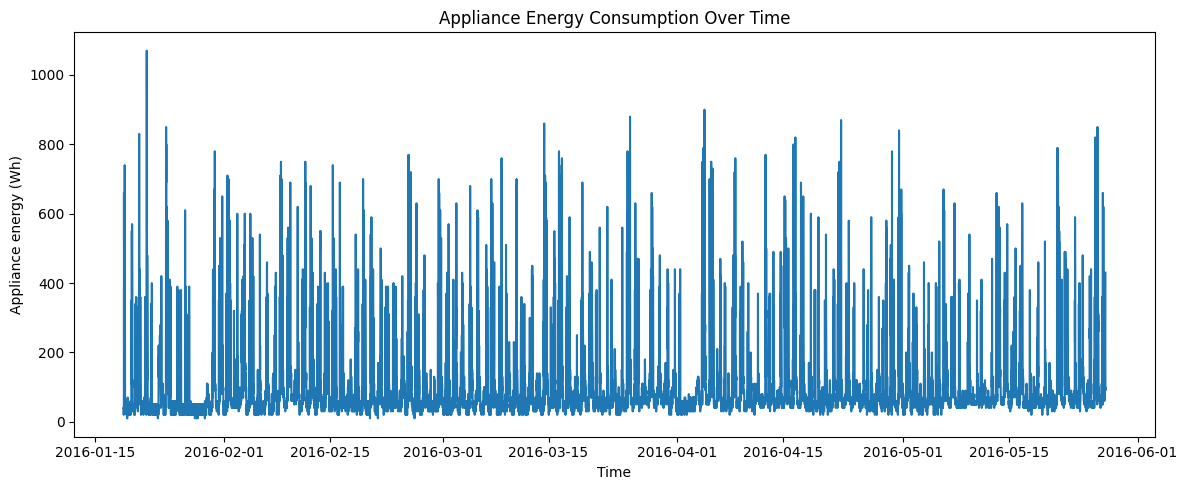

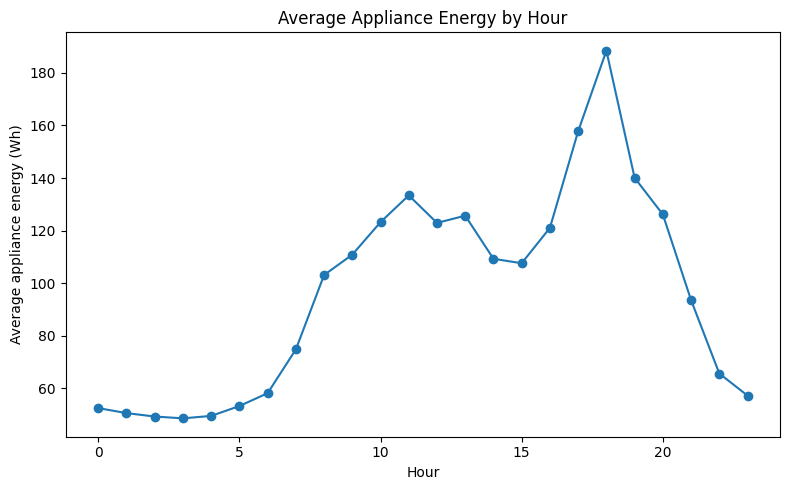

,Appliances
Appliances,1.000000
Appliances_lag_1,0.751074
Appliances_roll_max_3,0.665077
Appliances_roll_mean_3,0.648679
Appliances_roll_max_6,0.609470
Appliances_roll_mean_6,0.592315
Appliances_roll_max_12,0.569783
Appliances_roll_std_3,0.567502
Appliances_roll_mean_12,0.560906
Appliances_roll_std_6,0.560272


In [20]:
# 15. Energy exploratory analysis

plt.figure(figsize=(12, 5))
plt.plot(energy_features_df.index, energy_features_df["Appliances"])
plt.title("Appliance Energy Consumption Over Time")
plt.xlabel("Time")
plt.ylabel("Appliance energy (Wh)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "energy_time_series.png", dpi=300)
plt.show()

energy_hourly_profile = energy_features_df.groupby(
    energy_features_df.index.hour
)["Appliances"].mean()

plt.figure(figsize=(8, 5))
plt.plot(energy_hourly_profile.index, energy_hourly_profile.values, marker="o")
plt.title("Average Appliance Energy by Hour")
plt.xlabel("Hour")
plt.ylabel("Average appliance energy (Wh)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "energy_hourly_profile.png", dpi=300)
plt.show()

energy_corr = energy_features_df.corr(numeric_only=True)
display(energy_corr["Appliances"].sort_values(ascending=False).head(20))

In [21]:
# 16. Chronological energy split

energy_train, energy_valid, energy_test = chronological_split(energy_features_df)

ENERGY_TARGET = "Appliances"
energy_feature_cols = [
    c for c in energy_features_df.columns
    if c != ENERGY_TARGET and pd.api.types.is_numeric_dtype(energy_features_df[c])
]

Xe_train = energy_train[energy_feature_cols]
ye_train = energy_train[ENERGY_TARGET]

Xe_valid = energy_valid[energy_feature_cols]
ye_valid = energy_valid[ENERGY_TARGET]

Xe_test = energy_test[energy_feature_cols]
ye_test = energy_test[ENERGY_TARGET]

print("Energy train:", Xe_train.shape)
print("Energy validation:", Xe_valid.shape)
print("Energy test:", Xe_test.shape)

Energy train: (13108, 62)
Energy validation: (2809, 62)
Energy test: (2810, 62)


In [22]:
# 17. Energy baseline and model comparison

energy_models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=3,
            random_state=SEED
        ))
    ])
}

Xe_fit = pd.concat([Xe_train, Xe_valid])
ye_fit = pd.concat([ye_train, ye_valid])

energy_results_df, fitted_energy_models, energy_predictions, best_energy_name = compare_models(
    energy_train, energy_valid, energy_test, ENERGY_TARGET, energy_feature_cols, energy_models, "Energy")

energy_baseline_pred = energy_predictions["Naive Persistence"]
energy_baseline_rmse = float(energy_results_df.loc[energy_results_df["model"].eq("Naive Persistence"), "RMSE"].iloc[0])


Selected using validation: Ridge Regression


,dataset,model,MAE,RMSE,R2,MAPE_percent,RMSE_improvement_over_baseline_percent
0,Energy,Ridge Regression,27.072059,59.023944,0.573231,27.413383,NaN
1,Energy,Linear Regression,27.203833,59.053064,0.572810,27.702907,NaN
2,Energy,Gradient Boosting,34.354695,65.609254,0.472689,36.658650,NaN
3,Energy,Naive Persistence,26.059096,66.226146,0.462727,22.644335,NaN
4,Energy,Random Forest,41.743934,75.871238,0.294835,43.445834,NaN


,dataset,model,MAE,RMSE,R2,MAPE_percent,RMSE_improvement_over_baseline_percent,selected_on_validation
0,Energy,Ridge Regression,27.217144,60.094068,0.567954,24.462341,9.887434,True
1,Energy,Linear Regression,27.201764,60.107848,0.567756,24.426601,9.866772,False
2,Energy,Naive Persistence,26.747331,66.687778,0.467942,21.579947,0.000000,False
3,Energy,Random Forest,45.294154,73.220644,0.358593,50.714124,-9.796196,False
4,Energy,Gradient Boosting,66.599357,108.572534,-0.410284,88.057459,-62.807244,False


Best energy model: Ridge Regression


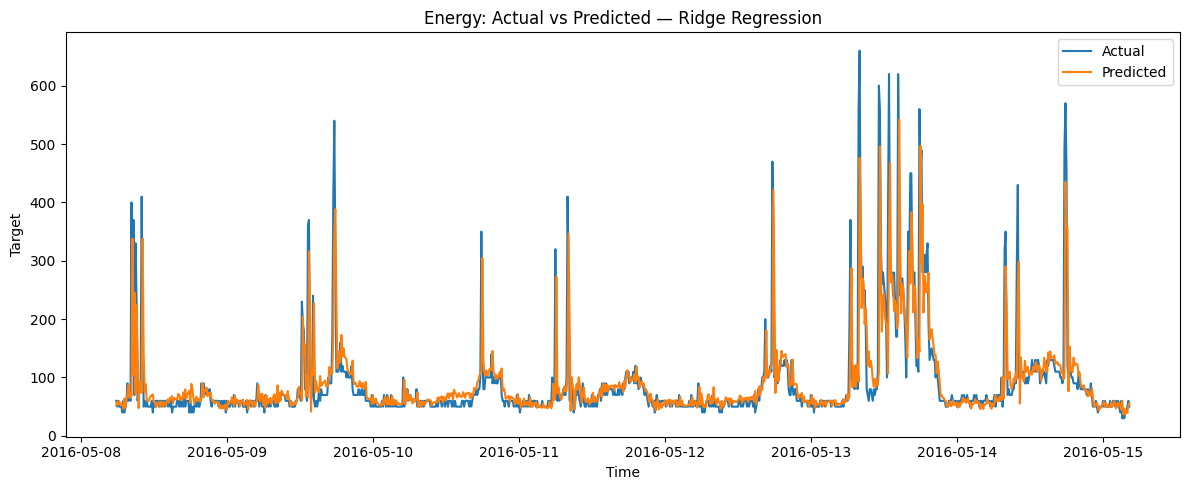

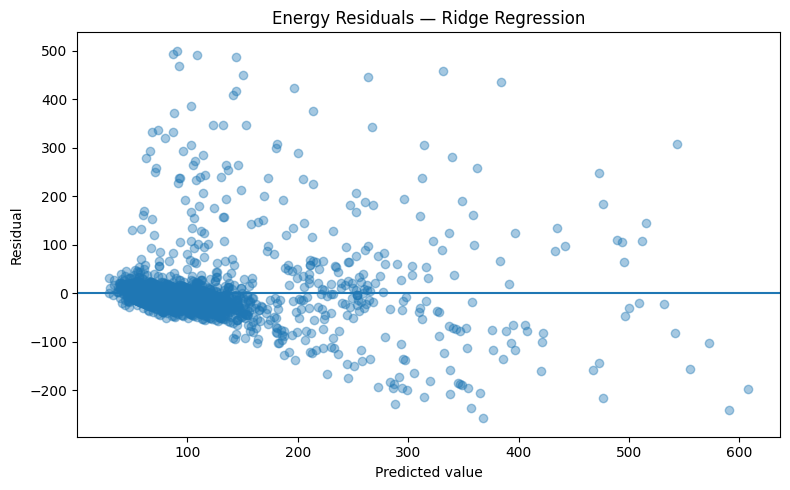

,feature,importance_mean,importance_std
44,Appliances_roll_max_3,110.561939,1.624450
43,Appliances_roll_std_3,26.780964,0.812490
35,Appliances_lag_1,19.930993,0.734532
36,Appliances_lag_2,18.275354,0.485235
37,Appliances_lag_3,8.866987,0.461429
48,Appliances_roll_mean_12,3.264709,0.286287
50,Appliances_roll_max_12,2.395324,0.201442
47,Appliances_roll_max_6,1.734464,0.253349
2,RH_1,1.363678,0.055593
42,Appliances_roll_mean_3,1.135909,0.210153


In [23]:
# 18. Select and interpret the best energy model

best_energy_model = fitted_energy_models.get(best_energy_name)
best_energy_pred = energy_predictions[best_energy_name]

print("Best energy model:", best_energy_name)

plot_actual_vs_predicted(
    ye_test,
    best_energy_pred,
    title=f"Energy: Actual vs Predicted — {best_energy_name}",
    output_name="energy_actual_vs_predicted.png"
)

plot_residuals(
    ye_test,
    best_energy_pred,
    title=f"Energy Residuals — {best_energy_name}",
    output_name="energy_residuals.png"
)

if best_energy_model is not None:
    joblib.dump(best_energy_model, MODEL_DIR / "best_energy_model.joblib")

if best_energy_model is not None:
    # Applies to Ridge and Linear Regression as well as tree models.
    perm = permutation_importance(best_energy_model, Xe_test, ye_test, n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error")
    energy_importance = pd.DataFrame({"feature": energy_feature_cols, "importance_mean": perm.importances_mean, "importance_std": perm.importances_std}).sort_values("importance_mean", ascending=False)
    display(energy_importance.head(20))
    energy_importance.to_csv(TABLE_DIR / "energy_feature_importance.csv", index=False)


# Part C — Model Parameters

Fixed parameters were specified before validation. No randomized search or time-series hyperparameter tuning is claimed in this run. Ridge uses alpha 1.0; Random Forest and Gradient Boosting retain the settings shown above.


In [24]:
# 19. Export the actual model settings
print("No hyperparameter search was performed. Model selection used validation RMSE.")


No hyperparameter search was performed. Model selection used validation RMSE.


# Part D — LSTM

LSTM was not included in this model comparison. It remains a possible extension rather than a reported experiment.


In [25]:
# 20. No LSTM results are reported.
RUN_LSTM = False


# Part E — Python-Based Virtual Smart-Home Simulation

The simulation is transparent and rule-based. It does not claim real physical control.

In [26]:
# 21. Water diagnostic output
water_sim = pd.DataFrame({"actual_meter_field": yw_test, "predicted_meter_field": best_water_pred}, index=yw_test.index)
water_saving_percent = np.nan
print("Water saving: not estimated. The meter field is not a verified water-volume target.")
water_sim.to_csv(TABLE_DIR / "water_diagnostic_predictions.csv")


Water saving: not estimated. The meter field is not a verified water-volume target.


In [27]:
# 22. Prediction-informed virtual energy scheduling
# At each peak interval, the previous information predicts available flexible energy.
# Actual flexible demand caps delivery; it is not used to plan the requested shift.
# Receiving intervals are predetermined off-peak slots within 24 hours.
# Their per-slot extra-load limit is fixed from training; future actual demand is not used.
# Baseline forecasts remain exogenous: this is a replay, not a closed-loop household model.
PEAK_HOURS = [17, 18, 19, 20, 21]  # 17:00 inclusive to 22:00 exclusive
FLEXIBLE_LOAD_FRACTION = 0.20
SHIFTABLE_PEAK_FRACTION = 0.50
RECEIVING_LIMIT_WH = float(ye_train.quantile(0.90) * 0.20)

def schedule_energy(actual, forecasts, flexible_fraction=0.20, shifted_fraction=0.50):
    sim = pd.DataFrame({"actual": actual, "predicted": np.maximum(np.asarray(forecasts), 0)}, index=actual.index)
    sim["is_peak"] = sim.index.hour.isin(PEAK_HOURS)
    sim["requested_shift"] = sim["predicted"] * flexible_fraction * shifted_fraction * sim["is_peak"]
    removed = np.zeros(len(sim)); added = np.zeros(len(sim))
    for i in np.flatnonzero(sim["is_peak"].to_numpy()):
        request = min(sim["requested_shift"].iloc[i], max(float(actual.iloc[i]), 0) * flexible_fraction)
        # Demand is removed only if it can be served inside the observed horizon.
        candidates = np.flatnonzero((sim.index > sim.index[i]) & (sim.index <= sim.index[i] + pd.Timedelta(hours=24)) & ~sim["is_peak"].to_numpy())
        for j in candidates:
            allocation = min(request, max(0., RECEIVING_LIMIT_WH - added[j]))
            added[j] += allocation; removed[i] += allocation; request -= allocation
            if request <= 1e-10: break
    sim["shifted_from_peak"] = removed
    sim["shifted_to_offpeak"] = added
    sim["simulated_scheduled"] = sim["actual"] - removed + added
    assert np.isclose(sim["actual"].sum(), sim["simulated_scheduled"].sum())
    assert (sim["simulated_scheduled"] >= -1e-8).all()
    assert (sim["shifted_to_offpeak"] <= RECEIVING_LIMIT_WH + 1e-8).all()
    peak = sim["is_peak"]
    baseline_peak = sim.loc[peak, "actual"].sum()
    reduction = 100 * sim.loc[peak, "shifted_from_peak"].sum() / baseline_peak if baseline_peak > 0 else np.nan
    return sim, reduction

energy_sim, peak_reduction_percent = schedule_energy(ye_test, best_energy_pred)
# A fixed clock-based schedule requests the training-set average peak demand.
fixed_forecast = np.full(len(ye_test), ye_train[ye_train.index.hour.isin(PEAK_HOURS)].mean())
fixed_sim, fixed_peak_reduction = schedule_energy(ye_test, fixed_forecast)
persistence_sim, persistence_peak_reduction = schedule_energy(ye_test, energy_baseline_pred)
policy_rows = []
for label,sim,reduction in [("Selected forecast",energy_sim,peak_reduction_percent),("Fixed schedule",fixed_sim,fixed_peak_reduction),("Persistence forecast",persistence_sim,persistence_peak_reduction)]:
    policy_rows.append({"policy":label,"peak_period_reduction_percent":reduction,"baseline_total_Wh":sim.actual.sum(),"scheduled_total_Wh":sim.simulated_scheduled.sum(),"maximum_interval_before_Wh":sim.actual.max(),"maximum_interval_after_Wh":sim.simulated_scheduled.max()})
policy_results = pd.DataFrame(policy_rows)
display(policy_results)
energy_sim.to_csv(TABLE_DIR / "energy_virtual_optimization.csv")
policy_results.to_csv(TABLE_DIR / "energy_policy_comparison.csv", index=False)
RUN_RECORD["simulation"] = {"peak_hours":PEAK_HOURS,"flexible_fraction":FLEXIBLE_LOAD_FRACTION,"shift_fraction":SHIFTABLE_PEAK_FRACTION,"receiving_limit_Wh":RECEIVING_LIMIT_WH,"maximum_delay_hours":24,"water_saving":"not estimated"}


,policy,peak_period_reduction_percent,baseline_total_Wh,scheduled_total_Wh,maximum_interval_before_Wh,maximum_interval_after_Wh
0,Selected forecast,9.843704,272610,272610.0,850,850.0
1,Fixed schedule,10.630516,272610,272610.0,850,850.0
2,Persistence forecast,9.745864,272610,272610.0,850,850.0


In [28]:
# 23. Sensitivity analysis under the same scheduling constraints
energy_sensitivity_rows = []
for flexible_fraction in [0.10, 0.15, 0.20, 0.25, 0.30]:
    for shifted_fraction in [0.25, 0.50, 0.75]:
        _, reduction = schedule_energy(ye_test, best_energy_pred, flexible_fraction, shifted_fraction)
        energy_sensitivity_rows.append({"flexible_load_fraction":flexible_fraction,"shifted_peak_fraction":shifted_fraction,"simulated_peak_reduction_percent":reduction})
energy_sensitivity = pd.DataFrame(energy_sensitivity_rows)
display(energy_sensitivity)
energy_sensitivity.to_csv(TABLE_DIR / "energy_sensitivity.csv", index=False)


,flexible_load_fraction,shifted_peak_fraction,simulated_peak_reduction_percent
0,0.10,0.25,2.483284
1,0.10,0.50,4.921852
2,0.10,0.75,7.116188
3,0.15,0.25,3.724926
4,0.15,0.50,7.382778
5,0.15,0.75,10.674283
6,0.20,0.25,4.966568
7,0.20,0.50,9.843704
8,0.20,0.75,14.232377
9,0.25,0.25,6.208210


In [29]:
# 24. Final summary and execution record
rows = []
for resource, results, selected, reduction in [("Water meter diagnostic",water_results_df,best_water_name,np.nan),("Energy",energy_results_df,best_energy_name,peak_reduction_percent)]:
    r = results.loc[results["model"].eq(selected)].iloc[0]
    rows.append({"resource":resource,"selected_model":selected,"MAE":r.MAE,"RMSE":r.RMSE,"R2":r.R2,"peak_reduction_percent":reduction})
final_summary = pd.DataFrame(rows)
display(final_summary)
final_summary.to_csv(TABLE_DIR / "final_summary.csv",index=False)
(OUTPUT_DIR / "run_record.json").write_text(json.dumps(RUN_RECORD, indent=2))
print("All outputs saved under:", OUTPUT_DIR)


,resource,selected_model,MAE,RMSE,R2,peak_reduction_percent
0,Water meter diagnostic,Naive Persistence,41.861472,79.818517,-0.837857,NaN
1,Energy,Ridge Regression,27.217144,60.094068,0.567954,9.843704


All outputs saved under: /content/outputs_corrected
